<a href="https://colab.research.google.com/github/mpolyakov84/LLM/blob/detectionDataset/hf_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip show langchain

Name: langchain
Version: 1.4.7
Summary: Building applications with LLMs through composability
Home-page: https://docs.langchain.com/
Author: 
Author-email: 
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: langchain-core, langgraph, pydantic
Required-by: 


In [ ]:
# !pip install -q langchain


In [ ]:
gpu_info = !nvidia-smi
gpu_info = '/n'.join(gpu_info)
if gpu_info.find('T4')>=0:
  print('Connected to T4')
else:
  print('No GPU')

No GPU


In [ ]:
# Restart kernel
import IPython
IPython.Application.instance().kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

In [ ]:
pip show datasets

Name: datasets
Version: 4.8.5
Summary: HuggingFace community-driven open-source library of datasets
Home-page: https://github.com/huggingface/datasets
Author: HuggingFace Inc.
Author-email: thomas@huggingface.co
License: Apache 2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: dill, filelock, fsspec, httpx, huggingface-hub, multiprocess, numpy, packaging, pandas, pyarrow, pyyaml, requests, tqdm, xxhash
Required-by: torchtune


In [1]:
from google.colab import userdata
from huggingface_hub import login
from transformers import pipeline

In [2]:
hf_token = userdata.get('HF_TOKEN')
assert  hf_token.startswith('hf_'), 'HF key has wrong value'
login(hf_token)

In [ ]:
classifier = pipeline('zero-shot-classification', model='roberta-large-mnli')
sequence_to_classify = "one day I will see the world"
candidate_labels = ['travel', 'cooking', 'dancing']
classifier(sequence_to_classify, candidate_labels)

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'one day I will see the world',
 'labels': ['travel', 'cooking', 'dancing'],
 'scores': [0.979964017868042, 0.010604963637888432, 0.009431004524230957]}

In [ ]:
sequence_to_classify = "I do not know what is going on in the world"
candidate_labels = ['positive', 'negative']
result = classifier(sequence_to_classify, candidate_labels)

In [ ]:
result

{'sequence': 'I do not know what is going on in the world',
 'labels': ['negative', 'positive'],
 'scores': [0.8742073774337769, 0.12579260766506195]}

In [ ]:
result['labels'][0]

'negative'

In [ ]:
import IPython
IPython.Application.instance().kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

In [3]:
from google.colab import userdata
from huggingface_hub import login
from transformers import pipeline

In [ ]:
detector = pipeline(model="facebook/detr-resnet-50")


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.9982852339744568,
  'label': 'airplane',
  'box': {'xmin': 153, 'ymin': 209, 'xmax': 419, 'ymax': 304}},
 {'score': 0.9995009899139404,
  'label': 'airplane',
  'box': {'xmin': 397, 'ymin': 619, 'xmax': 811, 'ymax': 801}},
 {'score': 0.9985529780387878,
  'label': 'airplane',
  'box': {'xmin': 434, 'ymin': 228, 'xmax': 714, 'ymax': 336}},
 {'score': 0.9984760880470276,
  'label': 'airplane',
  'box': {'xmin': 837, 'ymin': 198, 'xmax': 1102, 'ymax': 302}},
 {'score': 0.9991990923881531,
  'label': 'airplane',
  'box': {'xmin': 700, 'ymin': 368, 'xmax': 1011, 'ymax': 496}}]

In [ ]:
result = detector('/content/8b19784a38a9fea76c5930ad42f22a23.jpg')

In [ ]:
result[0]

{'score': 0.9982852339744568,
 'label': 'airplane',
 'box': {'xmin': 153, 'ymin': 209, 'xmax': 419, 'ymax': 304}}

In [ ]:
import plotly.express as px
import cv2
from PIL import Image

In [ ]:
# img = cv2.imread('/content/8b19784a38a9fea76c5930ad42f22a23.jpg')
img = Image.open('/content/8b19784a38a9fea76c5930ad42f22a23.jpg')
fig = px.imshow(img)

for detect in result:
    x0 = detect['box']['xmin']
    y0 = detect['box']['ymin']
    x1 = detect['box']['xmax']
    y1 = detect['box']['ymax']
    fig.add_shape(
        type="rect",
        x0=x0,
        y0=y0,
        x1=x1,
        y1=y1,
        line=dict(color="RoyalBlue", width=2),
        # fillcolor="LightSkyBlue",
        # opacity=1,
        # layer="below",  # Розміщує прямокутник під точками графіка
    )

fig.show()

# Load dataset

In [ ]:
!pip install -q ultralytics

In [5]:
from datasets import load_dataset
# from ultralytics.utils.downloads import unzip_file

In [ ]:
zip_path = '/content/drive/MyDrive/Colab Notebooks/LLM/lite_dataset.zip'
dataset_path = '/content'
unzip_file(file=zip_path,path=dataset_path)

Unzipping /content/drive/MyDrive/Colab Notebooks/LLM/lite_dataset.zip to /content/lite_dataset...: 100% ━━━━━━━━━━━━ 2402/2402 522.9files/s 4.6s


PosixPath('/content/lite_dataset')

In [ ]:
path = ('/content/lite_dataset')
dataset = load_dataset("imagefolder",data_dir=path)


Resolving data files:   0%|          | 0/2001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/401 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [ ]:
dataset['test']['objects']['categories']

Column([['F16'], ['C2'], ['E2'], ['Mig31', 'F35'], ['C5'], ...])

In [ ]:
dataset['test'][0]['objects']['bbox']

[[0.2552556818181818,
  0.28878281622911695,
  0.5099431818181818,
  0.5767700875099443]]

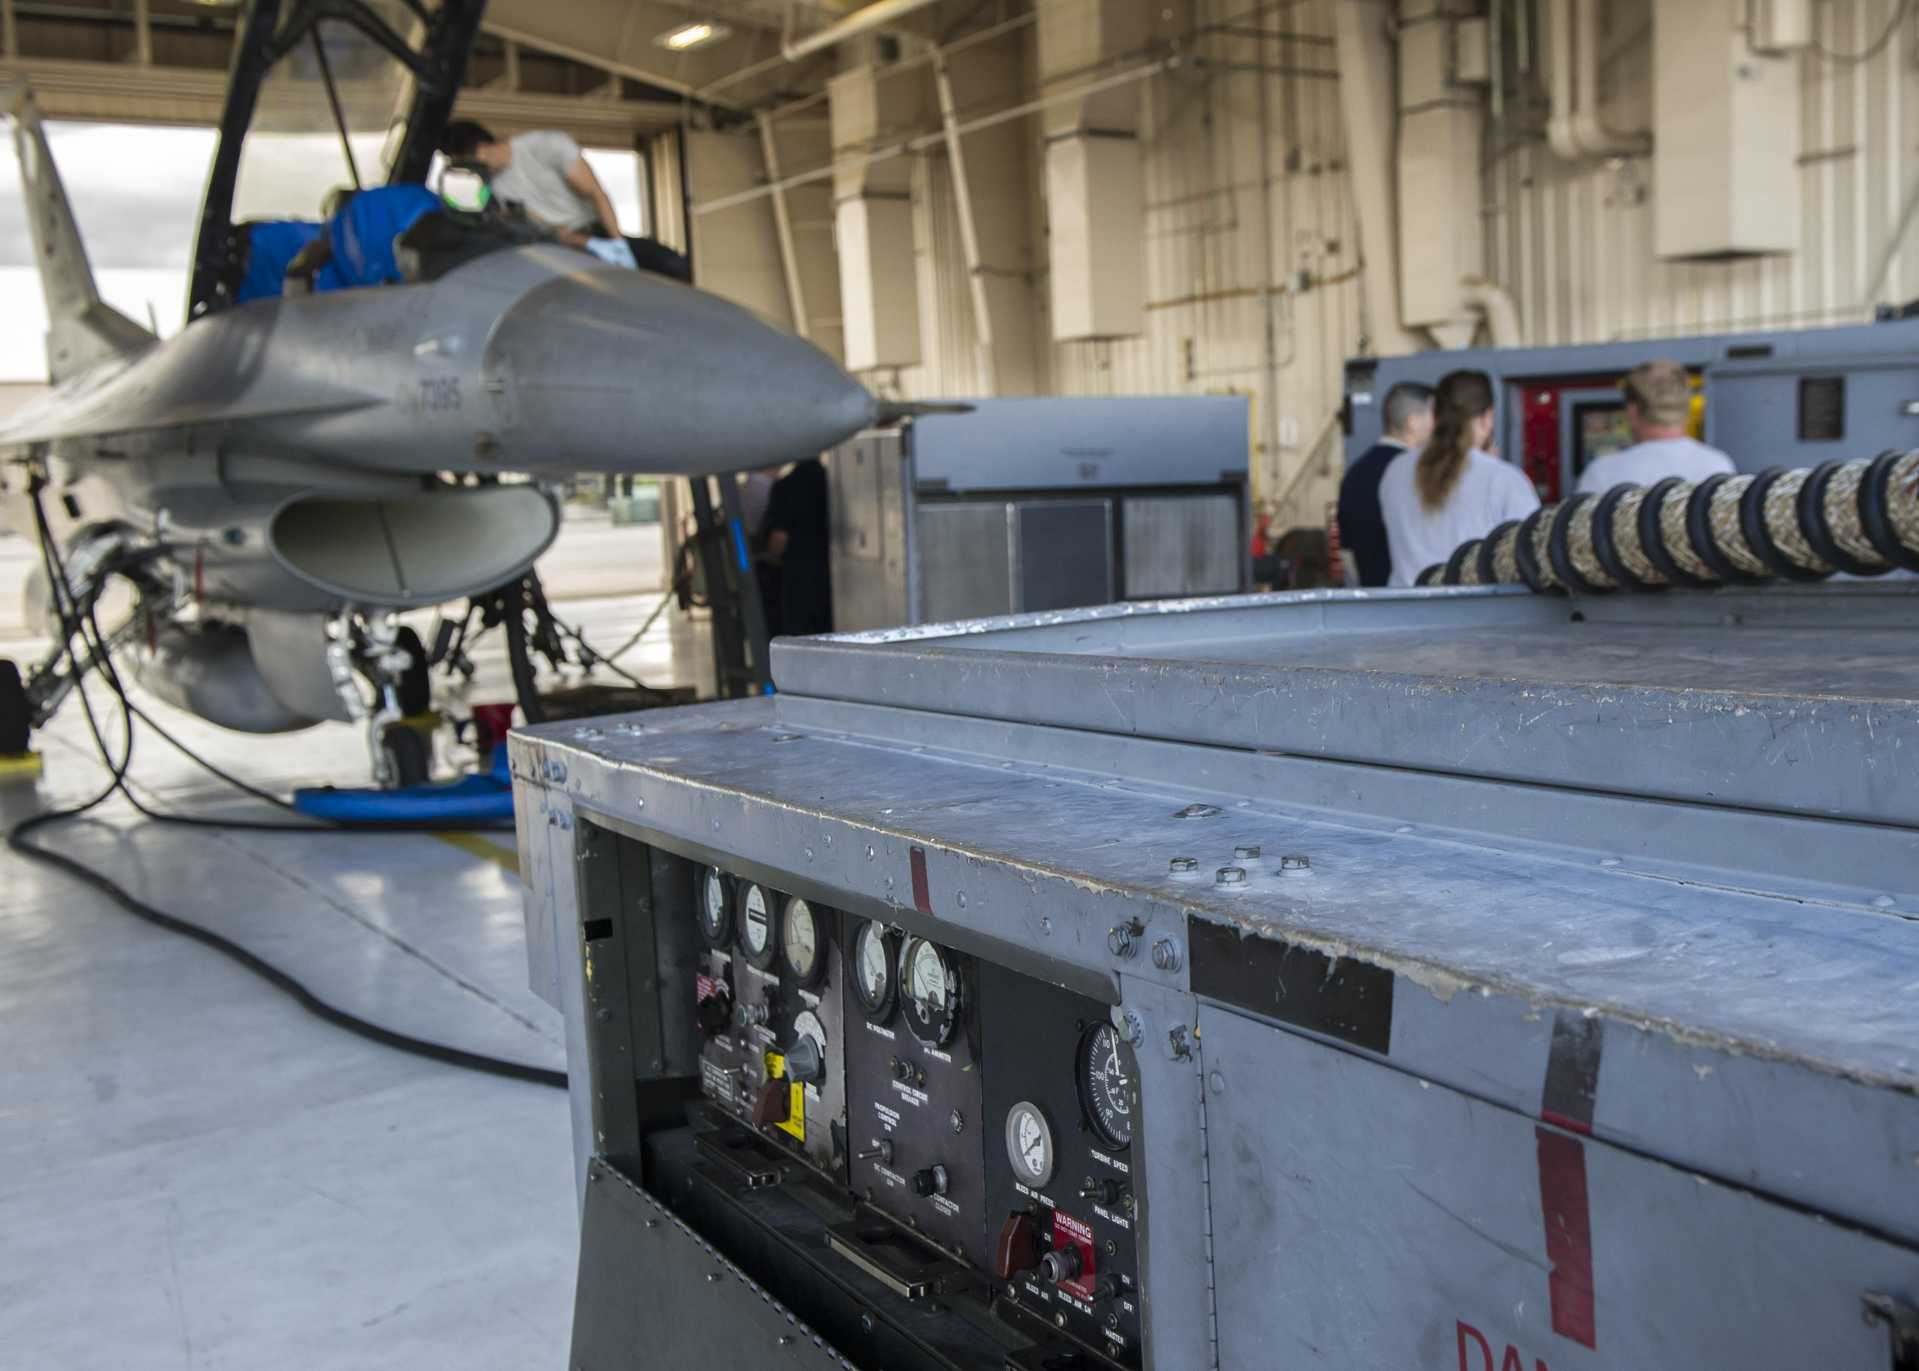

In [ ]:
dataset['test'][0]['image']

# Upload to huggingface

In [ ]:
dataset.push_to_hub(repo_id="mpolyakov7/aircraft")


Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (5 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/mpolyakov7/aircraft/commit/91c68b015a078f40a494a3643386d52c15c82943', commit_message='Upload dataset', commit_description='', oid='91c68b015a078f40a494a3643386d52c15c82943', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/mpolyakov7/aircraft', endpoint='https://huggingface.co', repo_type='dataset', repo_id='mpolyakov7/aircraft'), pr_revision=None, pr_num=None)

In [6]:
hf_ds = load_dataset('mpolyakov7/aircraft')

README.md:   0%|          | 0.00/499 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 80.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.9MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/200 [00:00<?, ? examples/s]

In [ ]:
hf_ds['test']['objects']['categories']

Column([['F16'], ['C2'], ['E2'], ['Mig31', 'F35'], ['C5'], ...])

In [12]:
type(hf_ds['test'][3]['image'])

PIL.JpegImagePlugin.JpegImageFile

[{'score': 0.9982852339744568,
  'label': 'airplane',
  'box': {'xmin': 153, 'ymin': 209, 'xmax': 419, 'ymax': 304}},

In [7]:
detector = pipeline(model="facebook/detr-resnet-50")

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

In [9]:
#TODO: Func for converting (x0,y0,x1,y1) to (x,y,w,h)
def convert_coord_to_xywh(box, size):
  dx = abs(box[2]-box[0])
  dy = abs(box[3]-box[1])
  x = (box[0] + dx/2)/size[0]
  y = (box[1] + dy/2)/size[1]
  w = dx/size[0]
  h = dy/size[1]
  return [x,y,w,h]

In [18]:
from PIL import Image
def pipeline_model(img):
  result = detector(img)
  bbox = []
  categories = []
  w,h = img.size
  size = (w,h)
  for item in result:
    x0 = item['box']['xmin']
    y0 = item['box']['ymin']
    x1 = item['box']['xmax']
    y1 = item['box']['ymax']

    box = [x0,y0,x1,y1]
    box_wh = convert_coord_to_xywh(box, size)

    bbox.append(box_wh)
    categories.append(item['label'])

  return {'bbox': bbox, 'categories': categories}


In [19]:
pipeline_model(hf_ds['test'][3]['image'])

{'bbox': [[0.5927132701421801,
   0.45111111111111113,
   0.0669431279620853,
   0.03288888888888889],
  [0.5082938388625592,
   0.7524444444444445,
   0.06279620853080568,
   0.027555555555555555]],
 'categories': ['airplane', 'airplane']}